In [ ]:
from pathlib import Path
import polars as pl
import pandas as pd
from sklearn.model_selection import train_test_split
import seaborn as sns
from matplotlib import pyplot as plt
import numpy as np
import statsmodels.api as sm

cwd = Path.cwd()
root = cwd.parent

# Note: Unzip cbecs2018_notebook file in the root directory to run this notebook

# Data
raw = pd.read_csv(root / 'cbecs2018_notebook/data/raw/cbecs2018_final_public.csv')

# codebook
df_labels = pl.read_csv(
    str(root / 'cbecs2018_notebook/data/raw/codebook_snapshot.csv'),
    has_header=True,
    skip_rows=1,
    infer_schema_length=0,
    ignore_errors=True,
)
df_labels = df_labels.rename({'Variable\norder':'order','Variable\nname':'name'})

# Features
numeric_candidates = ['SQFT', 'FLCEILHT', 'WKHRS', 'NWKER', 'MONUSE', 'HDD65', 'CDD65', 'HEATP', 'COOLP', 'OCCUPYP']
categorical_candidates = ['CENDIV', 'PBA', 'PUBCLIM', 'WLCNS', 'RFCNS', 'RFTILT', 'BLDSHP',
                          'GLSSPC', 'NFLOOR', 'YRCONC', 'ATTIC', 'MAINHT', 'MAINCL']

# Final training rows
training_IDs = pl.read_csv(str(root / 'cbecs2018_notebook/data/processed/split_membership.csv')).filter(pl.col('split')=='train')

In [3]:
# Preprocessesing and extracting training set. Leaving categoricals as sparse. 
# Including building IDs to validate training rows are consistent and consumption for EDA

def preprocess_train(raw:pd.DataFrame):
    SEED = 42
    missing_target = raw.MFBTU.isna()
    assert raw.loc[missing_target, 'ZMFBTU'].eq(9).all()
    data = raw.loc[~missing_target].sort_values('PUBID').copy()
    excluded = raw.loc[missing_target, ['PUBID', 'ZMFBTU']].copy()
    excluded['reason'] = 'MFBTU not applicable'
    assert data.MFBTU.ge(0).all() and np.isfinite(data.MFBTU).all()
    assert data.FINALWT.gt(0).all()
    fit_rows, held_out = train_test_split(data.index, test_size=0.30, random_state=SEED)
    validation_rows, test_rows = train_test_split(held_out, test_size=0.50, random_state=SEED)
    split_rows = {'train': sorted(fit_rows), 'validation': sorted(validation_rows), 'test': sorted(test_rows)}
    clean = data[numeric_candidates + categorical_candidates + ['PUBID','MFBTU']].copy()
    clean['FLCEILHT_gt50'] = clean.FLCEILHT.eq(995).astype(float)
    clean['FLCEILHT'] = clean.FLCEILHT.replace(995, 50)
    for col in ['MAINHT', 'MAINCL', 'HEATP', 'COOLP', 'OCCUPYP']:
        assert data.loc[data[col].isna(), 'Z' + col].eq(9).all()
    # for col in categorical_candidates:
    #     missing = 'not_applicable' if col in ['MAINHT', 'MAINCL'] else 'unknown'
    #     clean[col] = clean[col].map(lambda value: missing if pd.isna(value) else f'code_{int(value)}')
    clean['NFLOOR'] = clean.NFLOOR.replace({'code_994': '10_to_14', 'code_995': '15_or_more'})
    clean['PUBCLIM'] = clean.PUBCLIM.replace({'code_7': 'withheld'})

    return clean.loc[split_rows['train']]

In [4]:
df_train = pl.from_pandas(preprocess_train(raw), include_index=False)
assert df_train['PUBID'].to_list() == training_IDs['PUBID'].to_list()
# confirming training membership matches final output

In [5]:
# dictionary for categorical labels
def parse_format_codes(codes_str: str | None) -> dict:
    if not codes_str:
        return {}

    code_dict = {}
    for line in codes_str.strip().split("\n"):
        if "=" in line:
            code, label = line.split("=", 1)
            key = int(code.strip()) if code.strip().isdigit() else code.strip()
            code_dict[key] = label.strip()

    return code_dict

result_dict = {
    row["name"]: parse_format_codes(row["Values/Format codes"])
    for row in df_labels.filter(pl.col('name').is_in(categorical_candidates)).iter_rows(named=True)
}

result_dict['WLCNS'][4] = 'Aluminum, asbestos, plastic, or wood materials (siding, shingles, tiles'
result_dict['WLCNS'][5] = 'Sheet metal panels'


In [6]:
# Distribution of numeric features
df_train[numeric_candidates + ['MFBTU']].describe()

# Scale varies quite extremely across the features. These will need to be standardized before running regression or FFNN.
# OCCUPYP has a huge number of nulls. This will likely not be usable as a feature. 

statistic,SQFT,FLCEILHT,WKHRS,NWKER,MONUSE,HDD65,CDD65,HEATP,COOLP,OCCUPYP,MFBTU
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",4449.0,4449.0,4449.0,4449.0,4449.0,4449.0,4449.0,4198.0,4184.0,1258.0,4449.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,251.0,265.0,3191.0,0.0
"""mean""",172690.690717,13.764891,82.944032,214.238256,11.547314,4409.588222,1666.772758,88.545498,81.244025,88.970588,1.5868e7
"""std""",288108.99682,7.338674,52.351995,616.056126,1.616872,2159.082211,984.357503,22.978224,28.857038,15.808669,3.8262e7
"""min""",1001.0,7.0,0.0,0.0,0.0,402.0,10.0,0.0,1.0,13.0,160.0
"""25%""",12000.0,9.0,45.0,7.0,12.0,2575.0,939.0,90.0,75.0,81.0,663192.0
"""50%""",75000.0,11.0,60.0,40.0,12.0,4502.0,1461.0,100.0,100.0,96.0,4.397988e6
"""75%""",210000.0,15.0,125.0,150.0,12.0,5953.0,2125.0,100.0,100.0,100.0,1.575568e7
"""max""",2.1e6,50.0,168.0,7500.0,12.0,10666.0,5643.0,100.0,100.0,100.0,8.02588047e8


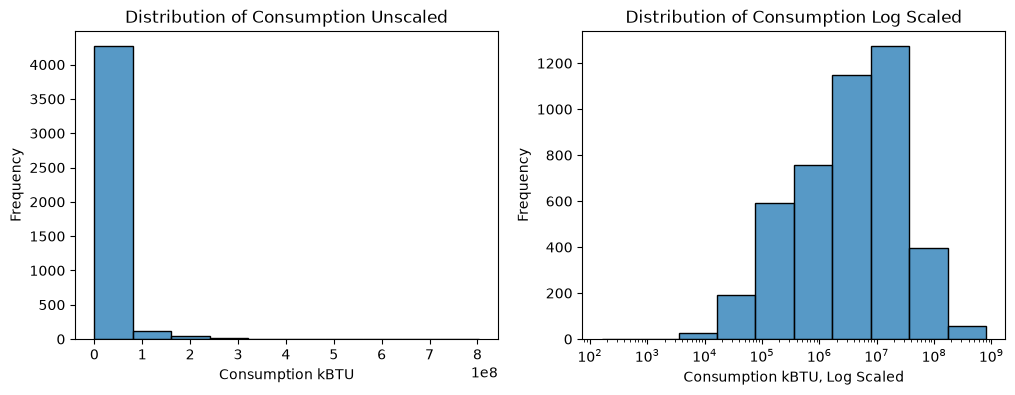

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df_train["MFBTU"].to_numpy(), bins=10, ax=axes[0])
axes[0].set_xlabel("Consumption kBTU")
axes[0].set_ylabel("Frequency")
axes[0].set_title("Distribution of Consumption Unscaled")

sns.histplot(df_train["MFBTU"].to_numpy(), bins=10, log_scale=True ,ax=axes[1])
axes[1].set_xlabel("Consumption kBTU, Log Scaled")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Distribution of Consumption Log Scaled")

plt.show()

# As expected, the outcome varies widely, with some extreme outliers beyond 100M kBTU driving right skewness. Log-scaled distribution looks fairly normal.

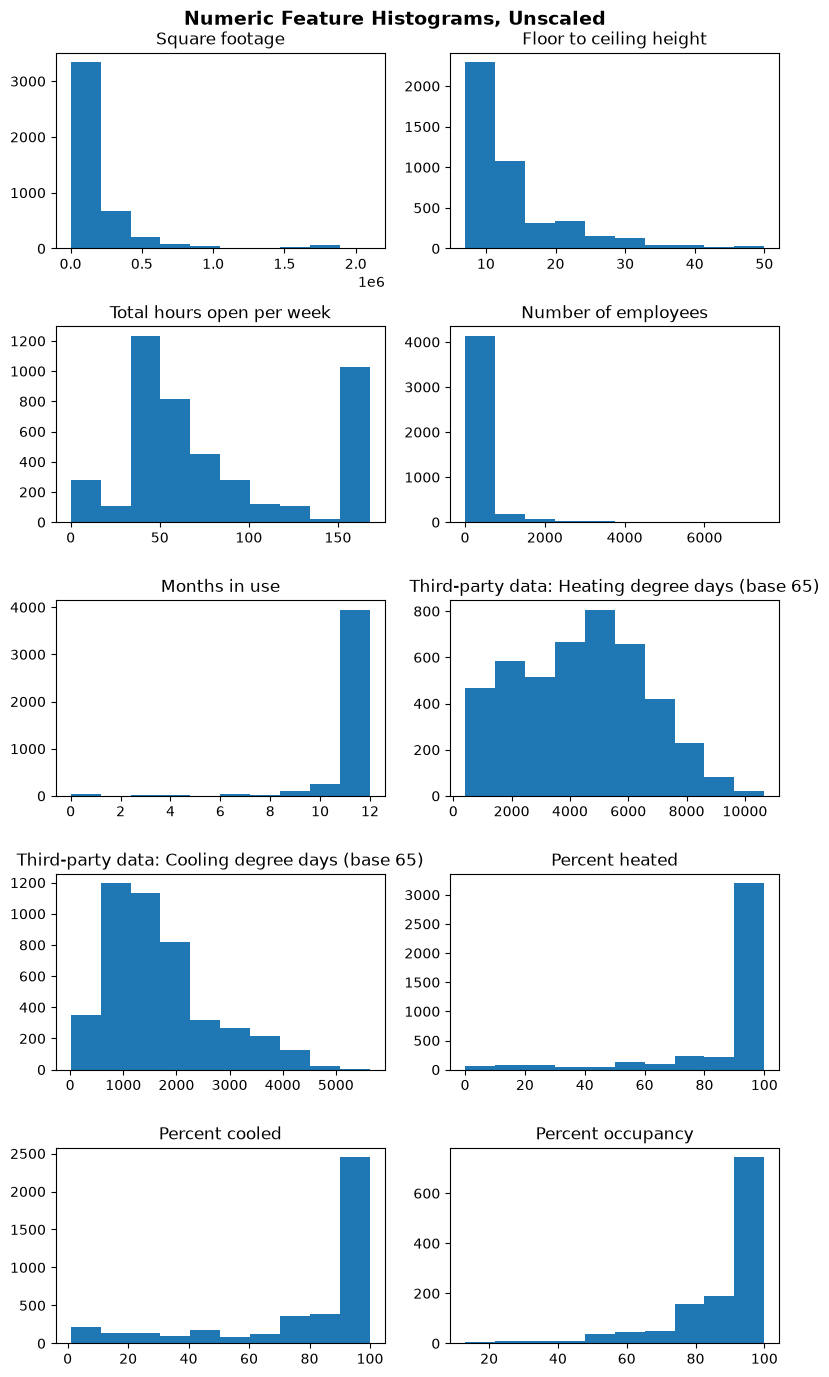

In [8]:
fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(8,14))
for i, ax in enumerate(axes.flatten()):
    var_name = numeric_candidates[i]
    ax.hist(df_train[var_name])
    label = df_labels.filter(pl.col('name')==var_name)['Label'].item()
    
    ax.set_title(label)

plt.suptitle('Numeric Feature Histograms, Unscaled', fontsize = 14, fontweight='bold')
plt.tight_layout()
plt.show()

Distributions for numeric features are mostly non-normal, but fairly intuitive. 

- Sqft: Most buildings are within 500K ft^2, except for a few outliers. This could benefit from log-scaling just to get a better sense of the distribution.

- Floor to ceiling height: This is also right-skewed, but less dramatically. Buildings with avg ceiling height > 20ft are probably places like theaters, gyms, etc..

- Total hours open: Somewhat multimodal. A few buildings are open < 40 hours/wk, but the plurality are open during normal business hours, 40 hrs/wk. Another cluster is open 24/7.

- Employees: Heavily right-skewed, with most buildings only housing < 1000 employees. 

- Months in use: Most buidlings are in use 12 mo./yr, so left skew for months in use makes sense.

- Degree days: Harder to interpret, although they are somewhat more normally distributed. Heating degrees and cooling degree days seem to imply there is more demand for heating than cooling at base 65 degrees.  

- Percent heated/cooled" Most buildings are entirely heated/cooled, with some lower-percentage outliers. These could be warehouses/industrial sites with adjacent offices, or partially unoccupied buildings. 

- Pct occupancy: Most buildings are fully occupied, although there is some left skewness for lower occupancies. <50% is extremely rare.

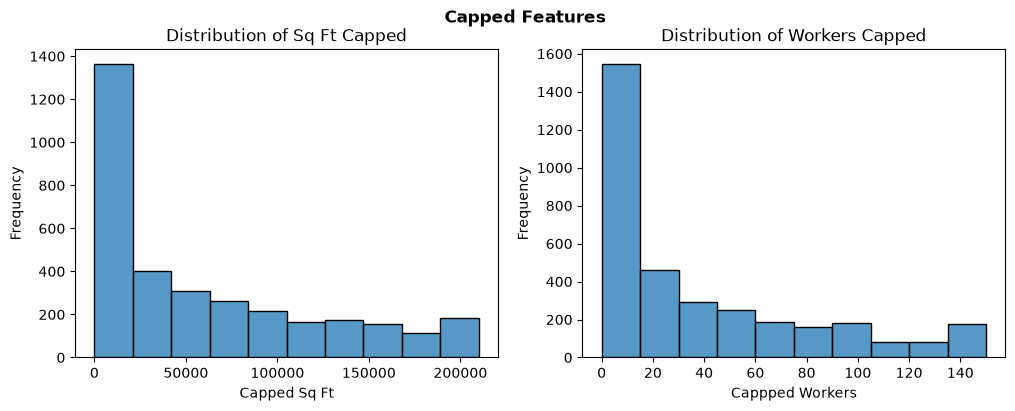

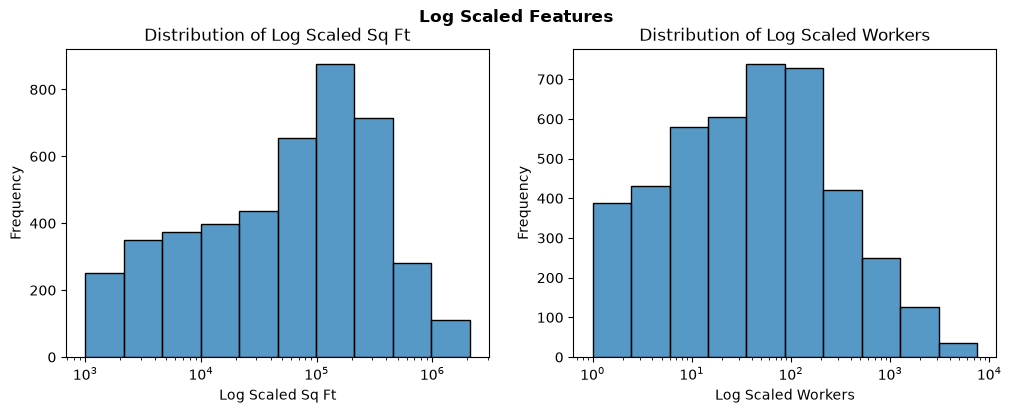

Buildings with 0 workers: 145
Buildings with 1 worker: 187
Buildings with <= 5 workers: 965



In [9]:
# arbitrary cutoff at 75th percentile just to see how most buildings are distributed for square footage and workers
q_sqft = df_train['SQFT'].quantile(0.75)
q_worker = df_train['NWKER'].quantile(0.75)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
q_75 = df_train['SQFT'].quantile(0.75)

sns.histplot(df_train["SQFT"].to_numpy(), bins=10, binrange=(0,q_sqft),ax=axes[0])
axes[0].set_xlabel("Capped Sq Ft")
axes[0].set_ylabel("Frequency")
axes[0].set_title("Distribution of Sq Ft Capped")

sns.histplot(df_train["NWKER"].to_numpy(), bins=10, binrange=(0,q_worker) ,ax=axes[1])
axes[1].set_xlabel("Cappped Workers")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Distribution of Workers Capped")

plt.suptitle('Capped Features',fontweight='bold')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df_train["SQFT"].to_numpy(), bins=10, log_scale=True, ax=axes[0])
axes[0].set_xlabel("Log Scaled Sq Ft")
axes[0].set_ylabel("Frequency")
axes[0].set_title("Distribution of Log Scaled Sq Ft")

sns.histplot(df_train["NWKER"].to_numpy(), bins=10, log_scale=True ,ax=axes[1])
axes[1].set_xlabel("Log Scaled Workers")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Distribution of Log Scaled Workers")
plt.suptitle('Log Scaled Features', fontweight='bold')
plt.show()

print(f"""Buildings with 0 workers: {df_train.filter(pl.col('NWKER')==0).height}
Buildings with 1 worker: {df_train.filter(pl.col('NWKER')==1).height}
Buildings with <= 5 workers: {df_train.filter(pl.col('NWKER')<=5).height}
""")
# Most buildings are fairly small and many have fewer than 200 workers at a given time; many have fewer than 5.

In [10]:
# spearman pairwise correlations for numeric features 
df_train.select(numeric_candidates + ['MFBTU']).to_pandas().corr(method='spearman')

# Sqft, work hours, and number of workers all strongly associated with consumption and with each other. 
# Heating degree days/cooling days are almost inverses of each other.
# Thin associations with the outcome and other variables. Sqft might be absorbing a lot of information.

,SQFT,FLCEILHT,WKHRS,NWKER,MONUSE,HDD65,CDD65,HEATP,COOLP,OCCUPYP,MFBTU
SQFT,1.000000,0.046285,0.388096,0.823643,0.028359,-0.017498,-0.015549,-0.012503,-0.020017,-0.279453,0.909231
FLCEILHT,0.046285,1.000000,-0.034475,-0.053931,0.111411,-0.040281,0.014130,-0.124113,-0.228780,-0.112338,-0.010888
WKHRS,0.388096,-0.034475,1.000000,0.353757,0.199752,0.011339,-0.022550,0.020598,0.104267,-0.109845,0.522386
NWKER,0.823643,-0.053931,0.353757,1.000000,0.061385,-0.039209,-0.004967,0.048805,0.099835,-0.220949,0.837756
MONUSE,0.028359,0.111411,0.199752,0.061385,1.000000,-0.032471,0.008001,-0.084776,0.007593,0.007094,0.080023
HDD65,-0.017498,-0.040281,0.011339,-0.039209,-0.032471,1.000000,-0.738615,0.199629,-0.074335,0.014419,0.043092
CDD65,-0.015549,0.014130,-0.022550,-0.004967,0.008001,-0.738615,1.000000,-0.114093,0.108697,-0.047611,-0.044700
HEATP,-0.012503,-0.124113,0.020598,0.048805,-0.084776,0.199629,-0.114093,1.000000,0.489333,0.216280,0.061719
COOLP,-0.020017,-0.228780,0.104267,0.099835,0.007593,-0.074335,0.108697,0.489333,1.000000,0.198009,0.096782
OCCUPYP,-0.279453,-0.112338,-0.109845,-0.220949,0.007094,0.014419,-0.047611,0.216280,0.198009,1.000000,-0.227764


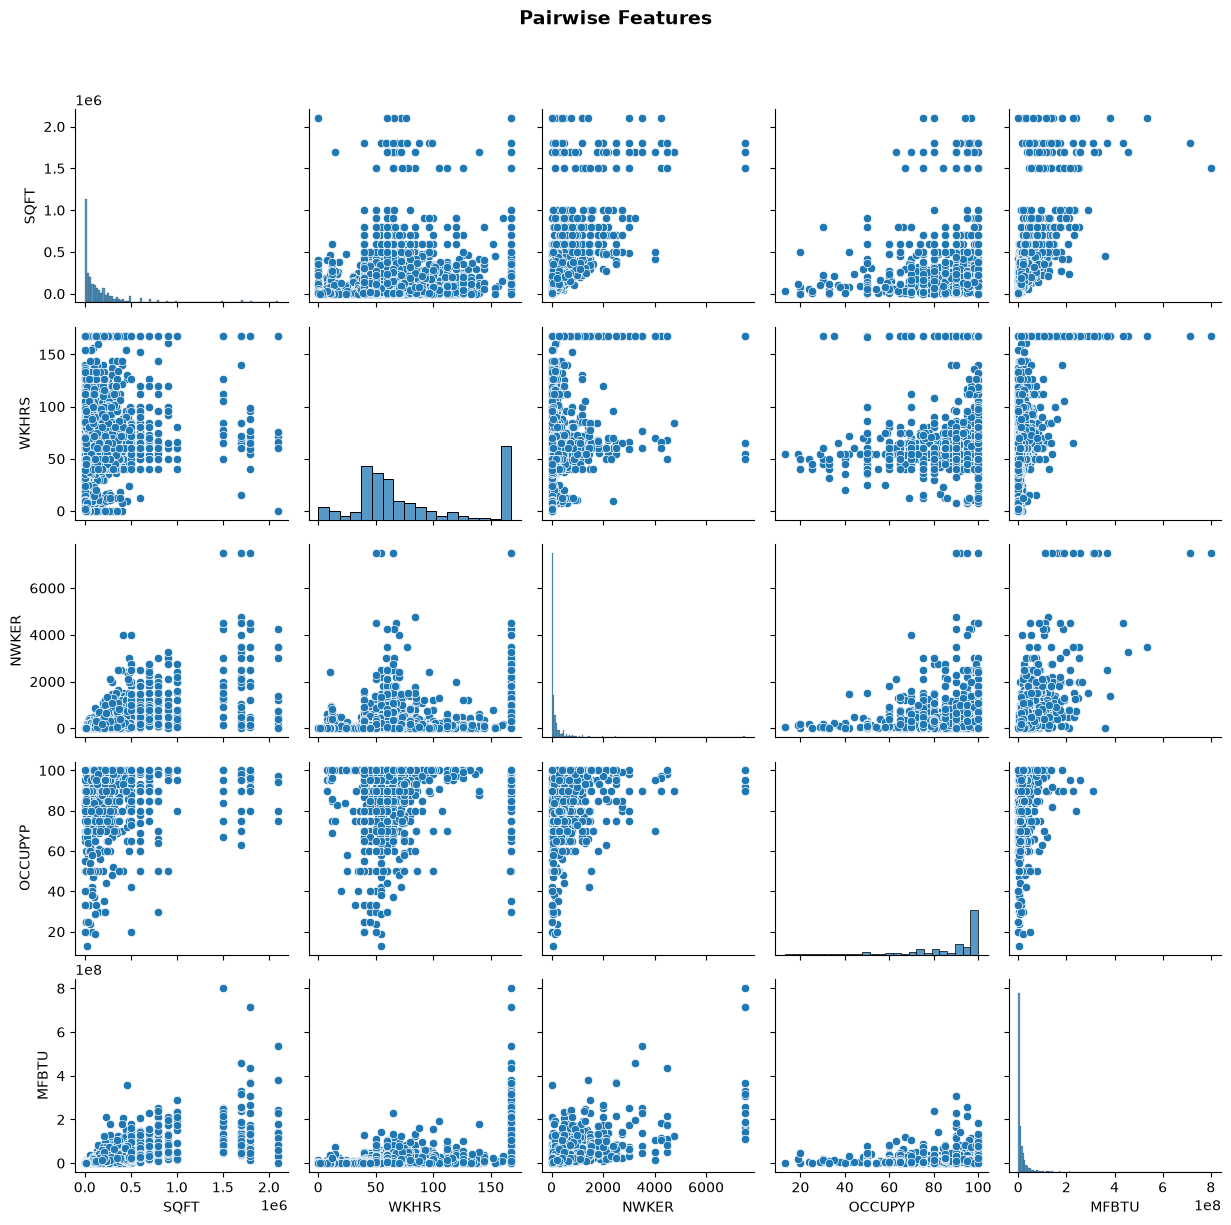

In [11]:
pairwise_features = ['SQFT','WKHRS','NWKER','OCCUPYP','MFBTU']

g = sns.pairplot(df_train.select(pairwise_features).to_pandas())
g.figure.suptitle("Pairwise Features", fontweight='bold', fontsize=14)
plt.subplots_adjust(top=0.9)
plt.show()

In [12]:
# categorical_candidates
df_plot = df_train.to_pandas()

# updating category labels for histograms (truncated text for labeling)
for col in categorical_candidates:
    labs = result_dict[col]
    df_plot[f'{col}_label'] = df_plot[col].map(
        lambda code: str(labs.get(code, code))[:12] 
    )

In [13]:
df_plot['CENDIV_label'].value_counts(sort=True)

CENDIV_label
South Atlant    909
East North C    711
Middle Atlan    581
Pacific         571
West South C    521
Mountain        373
West North C    348
East South C    235
New England     200
Name: count, dtype: int64

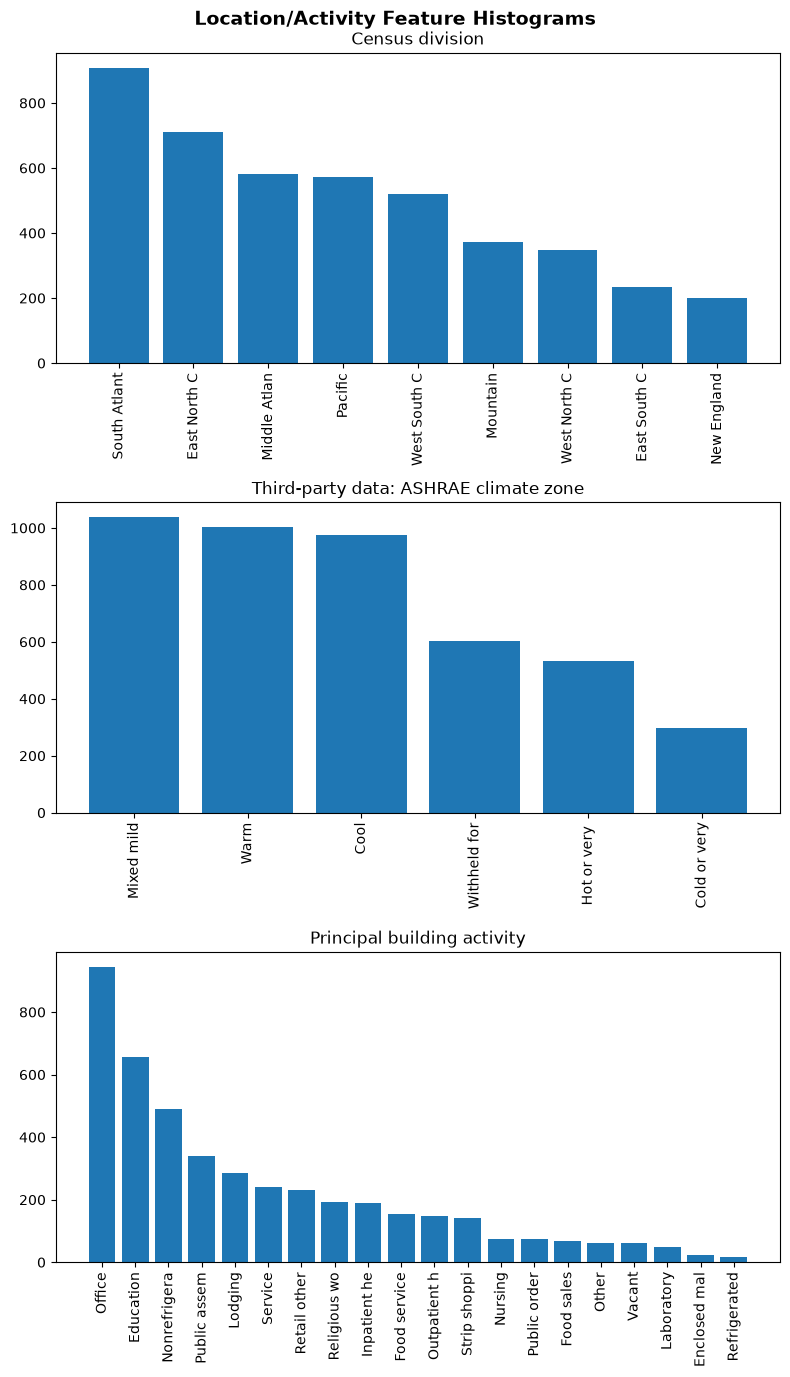

In [14]:
# Location and activity based features
loc_cat = ['CENDIV','PUBCLIM','PBA']

fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(8,14))
for i, ax in enumerate(axes.flatten()):
    var_name = f'{loc_cat[i]}_label'
    # label = df_labels.filter(pl.col('name')==var_name)['Label'].item()
    # vc = df_train[var_name].value_counts().sort(var_name)
    vc = df_plot[var_name].value_counts(sort=True)
    ax.bar(vc.index.astype(str), vc.values)
    # ax.bar(x_labels, counts)
    ax.tick_params(axis="x", rotation=90)
    label = df_labels.filter(pl.col('name')==loc_cat[i])['Label'].item()
    ax.set_title(label)

plt.suptitle('Location/Activity Feature Histograms', fontsize = 14, fontweight='bold')
plt.tight_layout()
plt.show()


# The most heavily populated areas generally have the most representation, although South Atlantic is more frequent than I would have expected. 
# A large number of climate datapoints are censored. This could overlap with census division anyway, or with the heating/cooling days features.

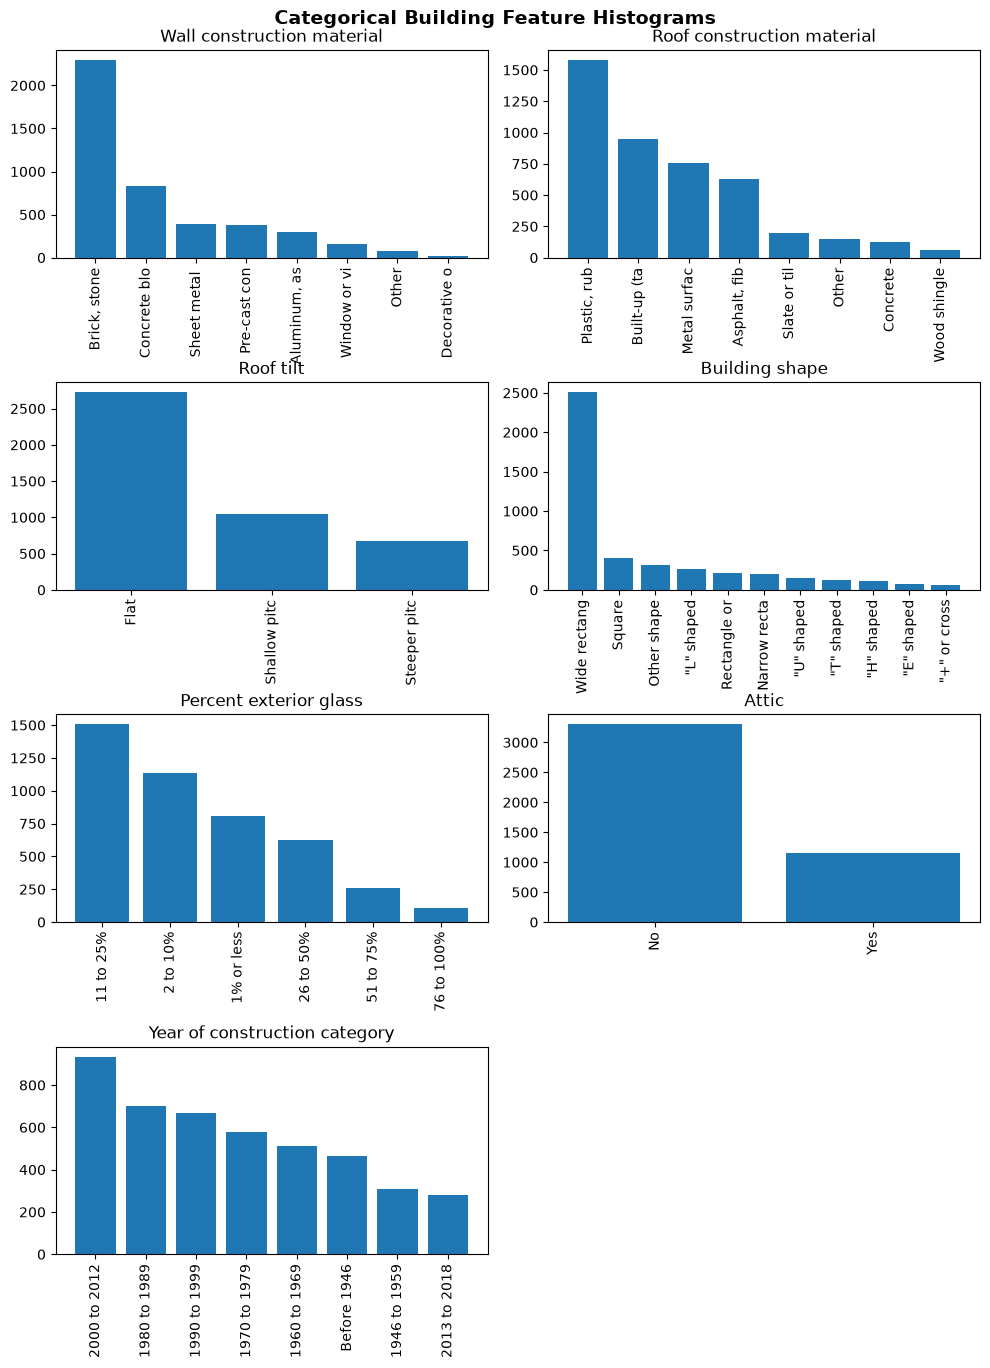

In [15]:
# building-based features
# NFLOOR
building_cat = ['WLCNS','RFCNS','RFTILT','BLDSHP','GLSSPC','ATTIC','YRCONC']

fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(10, 15))

for i, ax in enumerate(axes.flatten()):
    if i == 7:
        ax.axis('off')
        break
    var_name = f'{building_cat[i]}_label'
    # label = df_labels.filter(pl.col('name')==var_name)['Label'].item()
    # vc = df_train[var_name].value_counts().sort(var_name)
    vc = df_plot[var_name].value_counts(sort=True)
    ax.bar(vc.index.astype(str), vc.values)
    # var_name = building_cat[i]
    # vc = df_train[var_name].value_counts().sort(var_name)
    # codes = vc[var_name].to_list()
    # counts = vc['count'].to_list()  
    # x_labels = [
    #     str(result_dict.get(var_name, {}).get(c, c))[:10] 
    #     for c in codes
    # ]  
    # ax.bar(x_labels, counts)
    ax.tick_params(axis="x", rotation=90)
    title_label = df_labels.filter(pl.col('name') == building_cat[i])['Label'].item()
    ax.set_title(title_label)

plt.suptitle('Categorical Building Feature Histograms', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.subplots_adjust(bottom=0.15, hspace=0.6)  
plt.show()

# Wide, rectangular, and brick buildings dominate. Builds skew more recent, as expected.
# Intuitively, wall construction, year of construction, and glass percentage would be most likely to have some association with energy consumption due to insulation. Worth exploring.

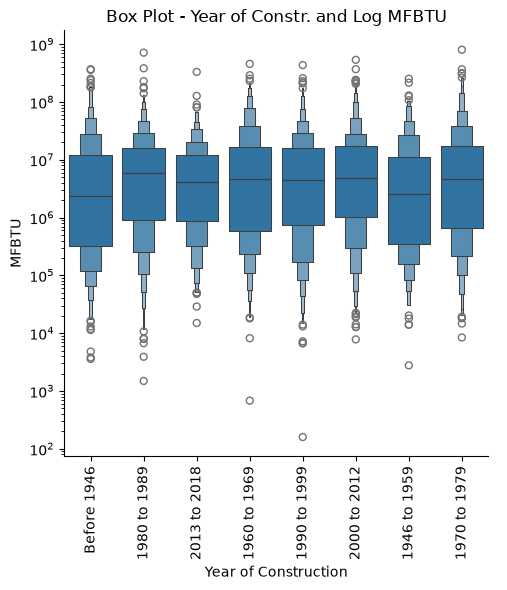

In [16]:
g = sns.catplot(
    data=df_plot, 
    x="YRCONC_label", 
    y="MFBTU", 
    log_scale=True,
    kind="boxen"
)
plt.xticks(rotation=90)
plt.xlabel('Year of Construction')
plt.title("Box Plot - Year of Constr. and Log MFBTU")
plt.show()

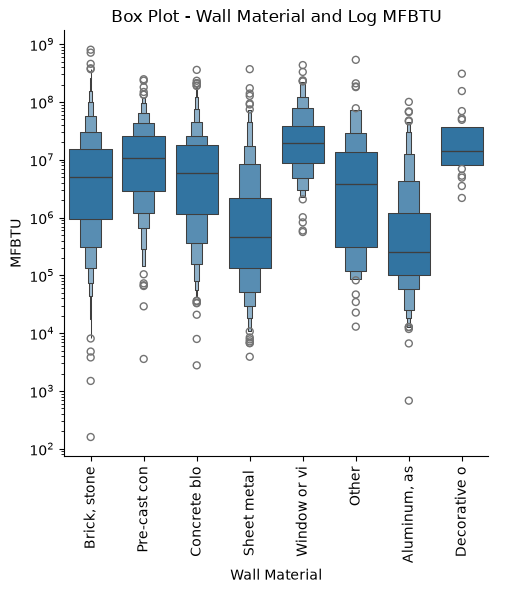

In [17]:
g = sns.catplot(
    data=df_plot, 
    x="WLCNS_label", 
    y="MFBTU", 
    log_scale=True,
    kind="boxen"
)
plt.xticks(rotation=90)
plt.xlabel('Wall Material')
plt.title("Box Plot - Wall Material and Log MFBTU")
plt.show()

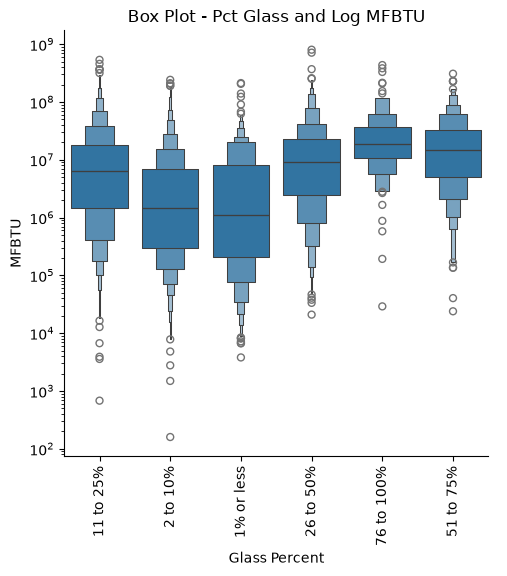

In [18]:
g = sns.catplot(
    data=df_plot, 
    x="GLSSPC_label", 
    y="MFBTU", 
    log_scale=True,
    kind="boxen"
)
plt.xticks(rotation=90)
plt.xlabel('Glass Percent')
plt.title("Box Plot - Pct Glass and Log MFBTU")
plt.show()

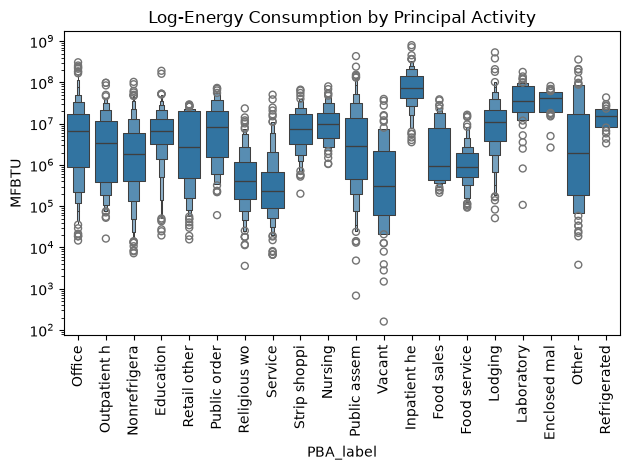

In [20]:
sns.boxenplot(
    df_plot,
    x='PBA_label',
    y='MFBTU'
    )
plt.title('Log-Energy Consumption by Principal Activity')
plt.xticks(rotation=90)
plt.yscale('log')
plt.tight_layout()
plt.show()

# More evidence of some association between PBA labels and varying consumption.
# Inpatient health, lodging, lab, and refrigerated warehouses are particularly high, which makes sense given the nature of these businesses.

We are interested in Energy Usage Intesity (EUI) as an alternative outcome for our model. 

EUI = MFBTU / SQFT

I'm going to add this as a variable and examine how the feature correlations change with respect to this other outcome. 

I'll also note that this target has some limitations as an outcome due to how the EIA handled square footage for buildings over 1M square feet. The SQFT value for each of these buildings is a shared average for *all* buildings over 1M sqft. This means EUI may be inaccurate for buildings of this size.  

In [21]:
# adding EUI
df_train = df_train.with_columns(
    EUI = pl.col('MFBTU') / pl.col('SQFT')
)

df_plot['EUI'] = df_plot.apply(lambda row: row.MFBTU / row.SQFT, axis=1)

# spearman correlations for EUI
sp_corr_eui = df_train.select(numeric_candidates + ['EUI']).to_pandas().corr(method='spearman').EUI

# spearman correlations for MFBTU
sp_corr_mfbtu = df_train.select(numeric_candidates + ['MFBTU']).to_pandas().corr(method='spearman').MFBTU

eui_vs_mfbtu = pd.concat([sp_corr_eui[:-1], sp_corr_mfbtu[:-1]], axis=1)
eui_vs_mfbtu['DELTA'] = eui_vs_mfbtu['EUI'] - eui_vs_mfbtu['MFBTU']

eui_vs_mfbtu

# The features that were more strongly associated with MFBTU are generally dilluted with respect to EUI. 
# A few of the less strongly associated features with MFBTU are *elevated* with respect to EUI, particularly the heating and cooling features.
# This implies SQFT is likely absorbing a lot of information about MFBTU. When it is built into the target, as is the case with EUI, features strongly associated with SQFT lose importance, while others gain importance.   

,EUI,MFBTU,DELTA
SQFT,0.132223,0.909231,-0.777007
FLCEILHT,-0.094553,-0.010888,-0.083665
WKHRS,0.473663,0.522386,-0.048723
NWKER,0.284339,0.837756,-0.553418
MONUSE,0.142385,0.080023,0.062362
HDD65,0.124181,0.043092,0.081088
CDD65,-0.073653,-0.044700,-0.028953
HEATP,0.163723,0.061719,0.102004
COOLP,0.251029,0.096782,0.154247
OCCUPYP,0.073623,-0.227764,0.301386


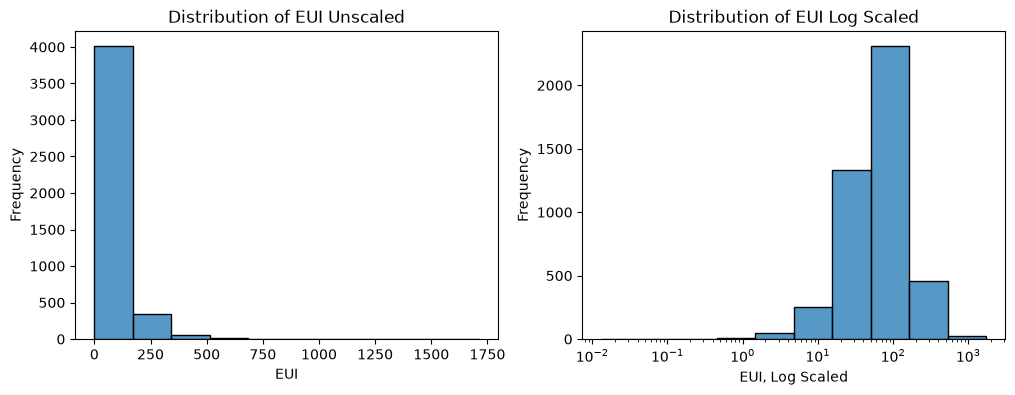

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df_train["EUI"].to_numpy(), bins=10, ax=axes[0])
axes[0].set_xlabel("EUI")
axes[0].set_ylabel("Frequency")
axes[0].set_title("Distribution of EUI Unscaled")

sns.histplot(df_train["EUI"].to_numpy(), bins=10, log_scale=True ,ax=axes[1])
axes[1].set_xlabel("EUI, Log Scaled")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Distribution of EUI Log Scaled")

plt.show()

# EUI is also heavily right-skewed and should be log-scaled for visualization.

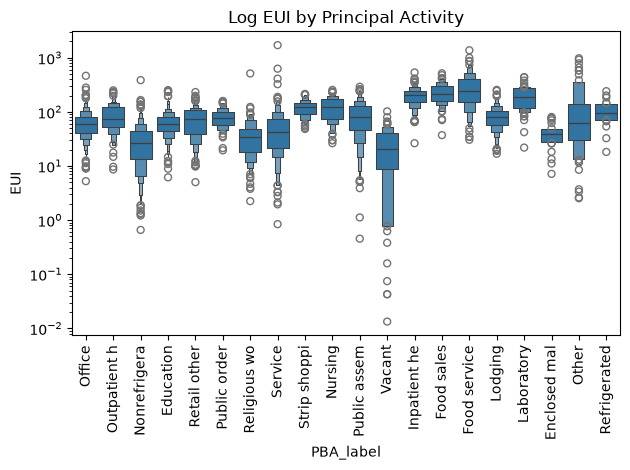

In [31]:
sns.boxenplot(
    df_plot,
    x='PBA_label',
    y='EUI',
    log_scale=True
    )
plt.title('Log EUI by Principal Activity')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Activity distributions look notably different for this outcome than for EUI. 
# Food service and food sales have some of the largest EUI averages. These settings may consume less energy overall than hospitals or laboratories, but are also less energy efficient.

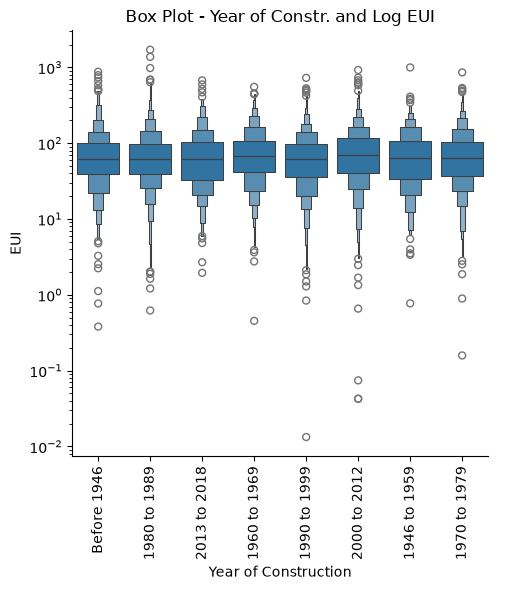

In [ ]:
g = sns.catplot(
    data=df_plot, 
    x="YRCONC_label", 
    y="EUI", 
    log_scale=True,
    kind="boxen"
)
plt.xticks(rotation=90)
plt.xlabel('Year of Construction')
plt.title("Box Plot - Year of Constr. and Log EUI")
plt.show()

# Very little difference in EUI across ranges of consruction years. 